In [ ]:
#recherche de la racine du projet pour trouver le dossier src
import sys
sys.path.append("..")
#importation des bibliothèques nécessaires
import pandas as pd
import matplotlib.pyplot as plt
#importation de la fonction load_allocine depuis le module src.data
from src.data import load_allocine

In [ ]:
#chargement des jeux de données Allociné
train = load_allocine("train")
val = load_allocine("validation")
test = load_allocine("test")

for nom, d in [("train", train), ("validation", val), ("test", test)]:
    print(nom, d.shape, d["label"].value_counts().to_dict())

train (160000, 2) {1: 80587, 0: 79413}
validation (20000, 2) {0: 10204, 1: 9796}
test (20000, 2) {0: 10408, 1: 9592}


In [ ]:
#recherche des avis vides dans les jeux de données
for nom, d in [("train", train), ("validation", val), ("test", test)]:
    vides = d["review"].isna() | d["review"].str.strip().eq("")
    print(nom, "→ avis vides :", vides.sum())

train → avis vides : 0
validation → avis vides : 0
test → avis vides : 0


In [ ]:
#recherche des doublons dans les jeux de données
for nom, d in [("train", train), ("validation", val), ("test", test)]:
    print(nom, "→ doublons :", d.duplicated(subset="review").sum())

train → doublons : 539
validation → doublons : 52
test → doublons : 72


In [ ]:
#recherche des avis du test et de la validation déjà présents dans le train
train_txt = set(train["review"])
print("Avis du test déjà présents dans le train :", test["review"].isin(train_txt).sum())
print("Avis de la validation déjà présents dans le train :", val["review"].isin(train_txt).sum())

Avis du test déjà présents dans le train : 34
Avis de la validation déjà présents dans le train : 32


In [ ]:
#vérification des avis du test déjà présents dans le train
test[test["review"].isin(train_txt)].head(10)

,review,label
3049,bien,1
3117,tres bien,1
3638,Une daube supplémentaire à éviter !!,0
4740,"Excellent ce film d'horreur, très effrayant et...",1
4956,Que dire de ce film totalement creux ? Rien du...,0
5187,Que dire de ce film sans aucun interet ? Absol...,0
5721,nul,0
7408,"Vraiment un bon film qui m'a bien étonné, à vo...",1
8035,Que dire de ce film sans aucun interet ? Absol...,0
8373,Que dire de ce film sans aucun interet ? Absol...,0


In [ ]:
# Nettoyage des jeux de données
def clean(d):
    d = d[d["review"].notna() & d["review"].str.strip().ne("")]
    return d.drop_duplicates(subset="review").reset_index(drop=True)

train = clean(train)
train_txt = set(train["review"])

val = clean(val)
val = val[~val["review"].isin(train_txt)].reset_index(drop=True)

test = clean(test)
test = test[~test["review"].isin(train_txt)].reset_index(drop=True)

for nom, d in [("train", train), ("validation", val), ("test", test)]:
    print(nom, d.shape, d["label"].value_counts().to_dict())

train (159461, 2) {1: 80334, 0: 79127}
validation (19920, 2) {0: 10166, 1: 9754}
test (19904, 2) {0: 10348, 1: 9556}


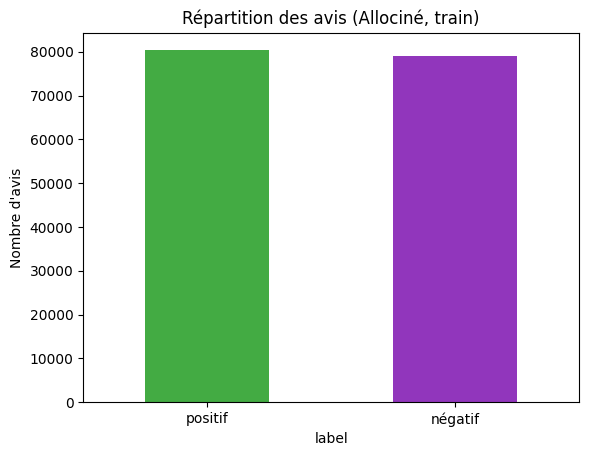

In [ ]:
#visualisation de la répartition des avis positifs et négatifs dans le jeu de données train
counts = train["label"].map({0: "négatif", 1: "positif"}).value_counts()

counts.plot(kind="bar", color=["#43ab43", "#9136bc"])
plt.title("Répartition des avis (Allociné, train)")
plt.ylabel("Nombre d'avis")
plt.xticks(rotation=0)
plt.show()

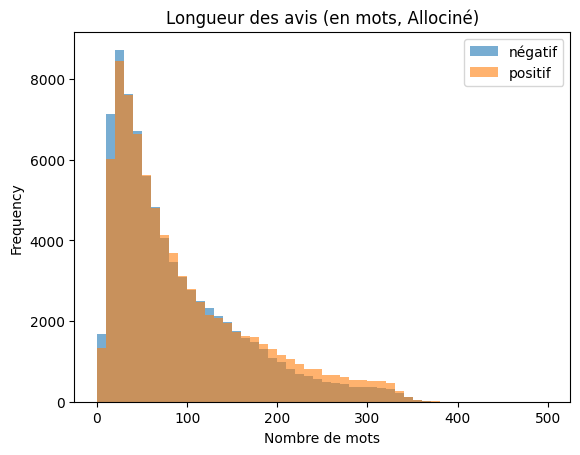

,count,mean,std,min,25%,50%,75%,max
label,,,,,,,,
0,79127.0,87.664678,72.641727,1.0,32.0,64.0,124.0,384.0
1,80334.0,95.132671,77.815321,1.0,35.0,69.0,136.0,377.0


In [ ]:
#visualisation de la longueur des avis (en mots) dans le jeu de données train
train["nb_mots"] = train["review"].str.split().str.len()

train.groupby("label")["nb_mots"].plot(kind="hist", bins=50, alpha=0.6, range=(0, 500))
plt.title("Longueur des avis (en mots, Allociné)")
plt.xlabel("Nombre de mots")
plt.legend(["négatif", "positif"])
plt.show()

train.groupby("label")["nb_mots"].describe()

## Conclusion de l'exploration — Allociné (Hugging Face)

**Source** : Allociné, `tblard/allocine` sur Hugging Face (licence MIT). Avis de spectateurs du site Allociné.fr, labels 0 = négatif, 1 = positif.

| Partition | Brut | Doublons internes | Fuites vers le train | Après nettoyage | Négatifs / Positifs |
|---|---|---|---|---|---|
| Train | 160 000 | 539 | — | **159 461** | 79 127 / 80 334 |
| Validation | 20 000 | 52 | 32 | **19 920** | 10 166 / 9 754 |
| Test | 20 000 | 72 | 34 | **19 904** | 10 348 / 9 556 |

Aucun avis vide.

| Classe (train) | Moyenne | Médiane | Min | Max |
|---|---|---|---|---|
| Négatif | 87,7 mots | 64 | 1 | 384 |
| Positif | 95,1 mots | 69 | 1 | 377 |

**Observations**
- Les classes sont équilibrées dans les trois partitions (environ 50/50, 52/48 en test).
- Les doublons sont surtout des avis très courts et génériques (« bien », « tres bien », « nul ») ou des avis copiés-collés plusieurs fois (« Que dire de ce film sans aucun interet ? … »).
- 66 avis de la validation et du test existaient déjà dans le train. Ils ont été retirés de la validation et du test (pas du train) pour éviter une fuite de données qui gonflerait les scores.
- Les avis sont longs (environ 91 mots en moyenne) avec une longue traîne jusqu'à environ 380 mots. Les avis positifs sont un peu plus longs (+7,5 mots en moyenne) et plus nombreux entre 200 et 350 mots, tandis que les avis négatifs dominent parmi les très courts (moins de 20 mots). Les deux distributions se recouvrent quand même largement : la longueur seule ne permet pas de distinguer le sentiment.

**Points forts** : très gros volume, partitions fournies par les auteurs, avis riches en contexte.
**Points faibles** : entraînement plus lourd (il faudra échantillonner, par exemple 20k en train et 5k en test). Certains avis n'ont pas d'accents (« tres bien »), ce qui disperse le vocabulaire.
